In [1]:
from pathlib import Path

import anndata as ad

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

normalized_path = (
    project_root / "data" / "interim"
    / "GSE176160_patients_normalized.h5ad"
)

normalized_adata = ad.read_h5ad(normalized_path, backed="r")

print("Normalized dataset shape:", normalized_adata.shape)
print("Normalization settings:", normalized_adata.uns["normalization"])
print("Donors:", normalized_adata.obs["Donor"].nunique())
print("Lanes:", normalized_adata.obs["Lane"].nunique())

Normalized dataset shape: (30589, 58735)
Normalization settings: {'counts_source': 'GSE176160_patients_qc.h5ad', 'method': 'total_count_scaling_then_log1p', 'target_sum': 10000}
Donors: 12
Lanes: 6


In [2]:
import numpy as np
import pandas as pd

detected_cells_per_gene = np.zeros(
    normalized_adata.n_vars,
    dtype=np.int64,
)

for expression_chunk, _, _ in normalized_adata.chunked_X(
    chunk_size=256
):
    chunk_detection_counts = np.asarray(
        (expression_chunk > 0).sum(axis=0)
    ).ravel()

    detected_cells_per_gene += chunk_detection_counts

gene_detection = pd.Series(
    detected_cells_per_gene,
    index=normalized_adata.var_names,
    name="n_cells_detected",
)

print("Total genes:", len(gene_detection))
print("Genes detected in zero cells:", gene_detection.eq(0).sum())
print("Genes detected in at least 3 cells:", gene_detection.ge(3).sum())

Total genes: 58735
Genes detected in zero cells: 20582
Genes detected in at least 3 cells: 32801


In [3]:
from scipy import sparse

eligible_gene_mask = gene_detection.ge(3).to_numpy()
eligible_genes = normalized_adata.var_names[eligible_gene_mask]

expression_chunks = []

for expression_chunk, _, _ in normalized_adata.chunked_X(chunk_size=256):
    expression_chunks.append(
        expression_chunk[:, eligible_gene_mask].tocsr()
    )

hvg_input = ad.AnnData(
    X=sparse.vstack(expression_chunks, format="csr"),
    obs=normalized_adata.obs.copy(),
    var=normalized_adata.var.loc[eligible_genes].copy(),
)
del expression_chunks

assert hvg_input.obs_names.equals(normalized_adata.obs_names)
assert hvg_input.var_names.equals(eligible_genes)

print("HVG input shape:", hvg_input.shape)
print("Matrix format:", hvg_input.X.format)

HVG input shape: (30589, 32801)
Matrix format: csr


In [4]:
import scanpy as sc

n_top_genes = 2_000

sc.pp.highly_variable_genes(
    hvg_input,
    flavor="seurat",
    n_top_genes=n_top_genes,
    batch_key=None,
    subset=False,
)

print("Eligible genes:", hvg_input.n_vars)
print("Selected HVGs:", hvg_input.var["highly_variable"].sum())

hvg_input.var.loc[
    hvg_input.var["highly_variable"],
    ["means", "dispersions", "dispersions_norm"],
].sort_values("dispersions_norm", ascending=False).head(10)

Eligible genes: 32801
Selected HVGs: 2000


,means,dispersions,dispersions_norm
index,,,
SST,0.100034,4.593617,18.536146
TNNC2,0.141938,3.990222,16.127884
MYL1,0.173947,3.947148,15.955967
CXCL8,0.005518,3.810817,15.411843
KISS1,0.022419,3.710298,15.010653
TTN,0.130079,3.697300,14.958776
MYLPF,0.371450,4.740835,14.914718
HCRT,0.027681,3.542029,14.339058
LINC00682,0.003625,3.529093,14.287430


In [5]:
n_hvgs = int(hvg_input.var["highly_variable"].sum())

sc.pp.pca(
    hvg_input,
    n_comps=50,
    mask_var="highly_variable",
    zero_center=True,
    svd_solver="arpack",
    random_state=0,
)

pca_coordinates = hvg_input.obsm["X_pca"]
variance_ratio = hvg_input.uns["pca"]["variance_ratio"]

assert pca_coordinates.shape == (hvg_input.n_obs, 50)
assert np.isfinite(pca_coordinates).all()

print("Selected HVGs:", n_hvgs)
print("PCA coordinates shape:", pca_coordinates.shape)
print(f"Variance explained by PC1: {variance_ratio[0]:.2%}")
print(f"Variance explained by first 10 PCs: {variance_ratio[:10].sum():.2%}")

Selected HVGs: 2000
PCA coordinates shape: (30589, 50)
Variance explained by PC1: 10.14%
Variance explained by first 10 PCs: 38.84%


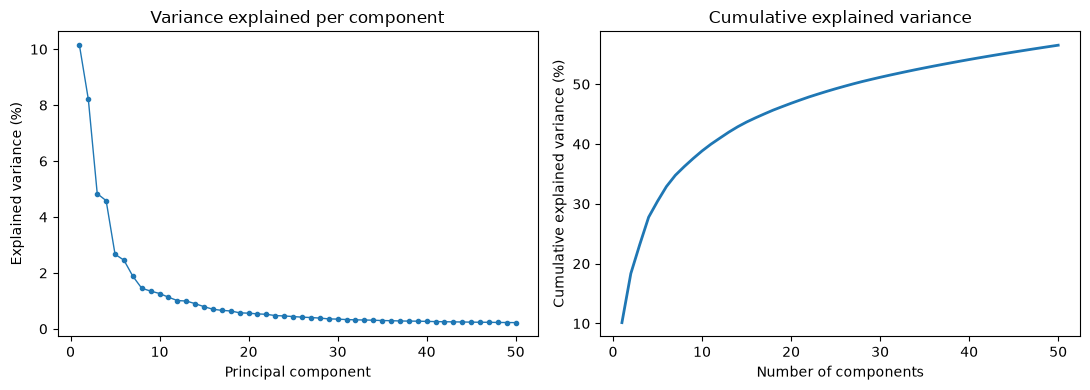

In [6]:
import matplotlib.pyplot as plt

pc_numbers = np.arange(1, len(variance_ratio) + 1)
variance_pct = variance_ratio * 100
cumulative_variance_pct = np.cumsum(variance_pct)

fig_pca_variance, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(pc_numbers, variance_pct, marker=".", linewidth=1)
axes[0].set_title("Variance explained per component")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance (%)")

axes[1].plot(pc_numbers, cumulative_variance_pct, linewidth=2)
axes[1].set_title("Cumulative explained variance")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative explained variance (%)")

fig_pca_variance.tight_layout()
plt.show()

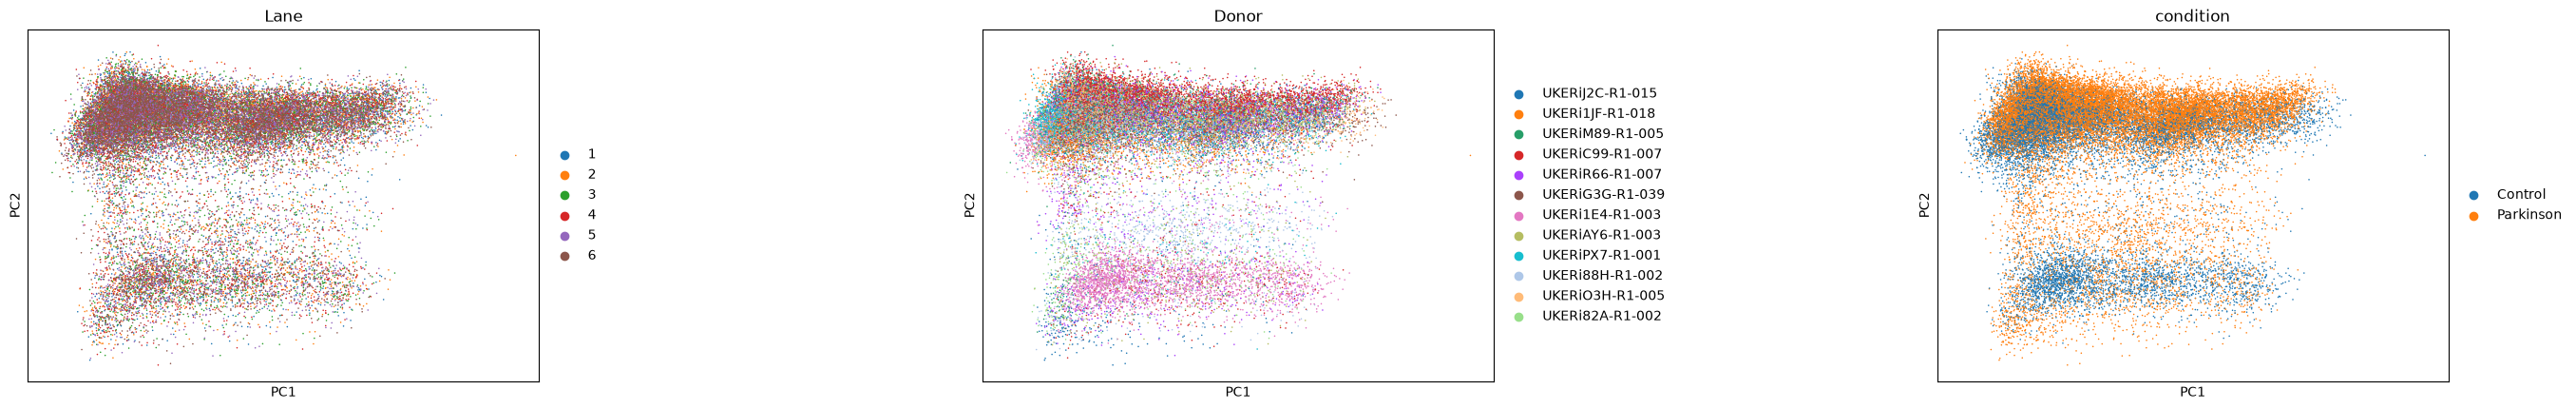

In [7]:
sc.pl.pca(
    hvg_input,
    color=["Lane", "Donor", "condition"],
    dimensions=(0, 1),
    ncols=3,
    size=5,
    wspace=0.7,
)

In [8]:
pc2_review = hvg_input.obs[["Donor", "condition"]].assign(
    PC2=pca_coordinates[:, 1]
)

pc2_cutoff = pc2_review["PC2"].quantile(0.20)
pc2_review["in_lower_pc2"] = pc2_review["PC2"].le(pc2_cutoff)

pc2_by_donor = (
    pc2_review
    .groupby(["Donor", "condition"], observed=True)
    .agg(
        n_cells=("PC2", "size"),
        n_lower_pc2=("in_lower_pc2", "sum"),
        median_pc2=("PC2", "median"),
    )
)

pc2_by_donor["pct_lower_pc2"] = (
    100 * pc2_by_donor["n_lower_pc2"] / pc2_by_donor["n_cells"]
)

pc2_by_donor.sort_values("pct_lower_pc2", ascending=False).round(2)

,,n_cells,n_lower_pc2,median_pc2,pct_lower_pc2
Donor,condition,,,,
UKERi1E4-R1-003,Control,3446,2503,-6.72,72.63
UKERi82A-R1-002,Control,857,513,-2.82,59.86
UKERi88H-R1-002,Parkinson,3279,881,0.72,26.87
UKERiR66-R1-007,Parkinson,2696,626,1.45,23.22
UKERiAY6-R1-003,Parkinson,2985,489,1.56,16.38
UKERiJ2C-R1-015,Parkinson,2171,344,1.17,15.85
UKERiC99-R1-007,Parkinson,4587,404,2.31,8.81
UKERiM89-R1-005,Parkinson,1034,75,1.81,7.25
UKERiPX7-R1-001,Parkinson,2157,125,1.32,5.80


In [9]:
pc2_loadings = pd.Series(
    hvg_input.varm["PCs"][:, 1],
    index=hvg_input.var_names,
    name="PC2_loading",
)

pc2_hvg_loadings = pc2_loadings.loc[
    hvg_input.var["highly_variable"]
]

pc2_loading_extremes = pd.concat(
    [
        pc2_hvg_loadings.nsmallest(10),
        pc2_hvg_loadings.nlargest(10),
    ],
    keys=["Negative", "Positive"],
    names=["direction", "gene"],
)

pc2_loading_extremes.to_frame().round(4)

PC2_loading
direction gene                
Negative  LGALS1       -0.2679
          COL3A1       -0.2091
          LUM          -0.1797
          COL1A2       -0.1781
          COL1A1       -0.1497
          S100A11      -0.1381
          S100A4       -0.1242
          SNHG5        -0.1172
          S100A6       -0.1042
          PEG10        -0.0895
Positive  FABP7         0.2990
          TUBA1A        0.1999
          CKB           0.1985
          IGFBP5        0.1661
          FGFBP3        0.1568
          SOX11         0.1018
          PRTG          0.0998
          RBP1          0.0988
          CSRP2         0.0977
          TSC22D1       0.0952

In [10]:
marker_genes = ["LUM", "LGALS1", "FABP7"]

marker_expression = pd.DataFrame(
    hvg_input[:, marker_genes].X.toarray(),
    index=hvg_input.obs_names,
    columns=marker_genes,
)

marker_review = pc2_review.join(
    marker_expression,
    validate="one_to_one",
)

marker_by_donor_region = (
    marker_review
    .groupby(["Donor", "condition", "in_lower_pc2"], observed=True)
    .agg(
        n_cells=("PC2", "size"),
        mean_LUM=("LUM", "mean"),
        mean_LGALS1=("LGALS1", "mean"),
        mean_FABP7=("FABP7", "mean"),
    )
)

focus_donors = ["UKERi1E4-R1-003", "UKERi82A-R1-002"]

marker_by_donor_region.loc[focus_donors].round(3)

n_cells  mean_LUM  mean_LGALS1  \
Donor           condition in_lower_pc2                                   
UKERi1E4-R1-003 Control   False             943     0.080        0.160   
                          True             2503     2.022        2.406   
UKERi82A-R1-002 Control   False             344     0.052        0.406   
                          True              513     0.370        2.432   

                                        mean_FABP7  
Donor           condition in_lower_pc2              
UKERi1E4-R1-003 Control   False              1.759  
                          True               0.350  
UKERi82A-R1-002 Control   False              2.474  
                          True               0.395

In [11]:
pc2_lane_review = pc2_review.assign(
    Lane=hvg_input.obs["Lane"]
)

pc2_by_focus_donor_lane = (
    pc2_lane_review.loc[
        pc2_lane_review["Donor"].isin(focus_donors)
    ]
    .groupby(["Donor", "Lane"], observed=True)
    .agg(
        n_cells=("PC2", "size"),
        median_pc2=("PC2", "median"),
        fraction_lower_pc2=("in_lower_pc2", "mean"),
    )
)

pc2_by_focus_donor_lane["pct_lower_pc2"] = (
    100 * pc2_by_focus_donor_lane.pop("fraction_lower_pc2")
)

pc2_by_focus_donor_lane.round(2)

n_cells  median_pc2  pct_lower_pc2
Donor           Lane                                    
UKERi1E4-R1-003 1         528       -6.60          71.40
                2         577       -6.74          71.92
                3         597       -6.88          74.54
                4         603       -6.77          75.46
                5         573       -6.75          71.03
                6         568       -6.60          71.13
UKERi82A-R1-002 1         132       -2.51          59.85
                2         161       -3.08          58.39
                3         158       -3.51          60.76
                4         138       -3.46          62.32
                5         138       -3.18          58.70
                6         130       -2.27          59.23

In [12]:
donor_design = pd.get_dummies(
    hvg_input.obs["Donor"], dtype=float
).to_numpy()

lane_design = pd.get_dummies(
    hvg_input.obs["Lane"], drop_first=True, dtype=float
).to_numpy()

donor_lane_design = np.column_stack([donor_design, lane_design])


def residual_sum_of_squares(design, scores):
    coefficients = np.linalg.lstsq(design, scores, rcond=None)[0]
    residuals = scores - design @ coefficients
    return np.square(residuals).sum(axis=0)


rss_donor = residual_sum_of_squares(donor_design, pca_coordinates)
rss_donor_lane = residual_sum_of_squares(
    donor_lane_design, pca_coordinates
)

lane_effect_by_pc = pd.DataFrame(
    {
        "explained_variance_pct": 100 * variance_ratio,
        "pct_remaining_variance_explained_by_lane": (
            100 * (rss_donor - rss_donor_lane) / rss_donor
        ),
    },
    index=[f"PC{i}" for i in range(1, len(variance_ratio) + 1)],
)

lane_effect_by_pc.nlargest(
    10, "pct_remaining_variance_explained_by_lane"
).round(2)

,explained_variance_pct,pct_remaining_variance_explained_by_lane
PC37,0.28,2.09
PC40,0.27,1.71
PC45,0.24,1.25
PC48,0.23,0.92
PC25,0.44,0.90
PC30,0.35,0.88
PC33,0.32,0.77
PC49,0.23,0.76
PC23,0.47,0.65
PC5,2.67,0.59


In [13]:
tables_dir = project_root / "results" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

hvg_summary = hvg_input.var[
    ["highly_variable", "means", "dispersions_norm"]
].assign(
    n_cells_detected=gene_detection.reindex(hvg_input.var_names)
)

pca_diagnostics = lane_effect_by_pc.assign(
    cumulative_variance_pct=(
        lane_effect_by_pc["explained_variance_pct"].cumsum()
    )
)

hvg_summary.to_csv(tables_dir / "hvg_selection.csv", index_label="gene")
pca_diagnostics.to_csv(
    tables_dir / "pca_variance_and_lane.csv",
    index_label="component",
)
pc2_by_donor.to_csv(tables_dir / "pca_pc2_by_donor.csv")

print("Genes in the HVG table:", len(hvg_summary))
print("PCs in the diagnostics table:", len(pca_diagnostics))

Genes in the HVG table: 32801
PCs in the diagnostics table: 50


Saved figure: pca_explained_variance.png
Saved figure: pca_explained_variance.pdf
Saved figure: pca_by_lane_donor_condition.png
Saved figure: pca_by_lane_donor_condition.pdf


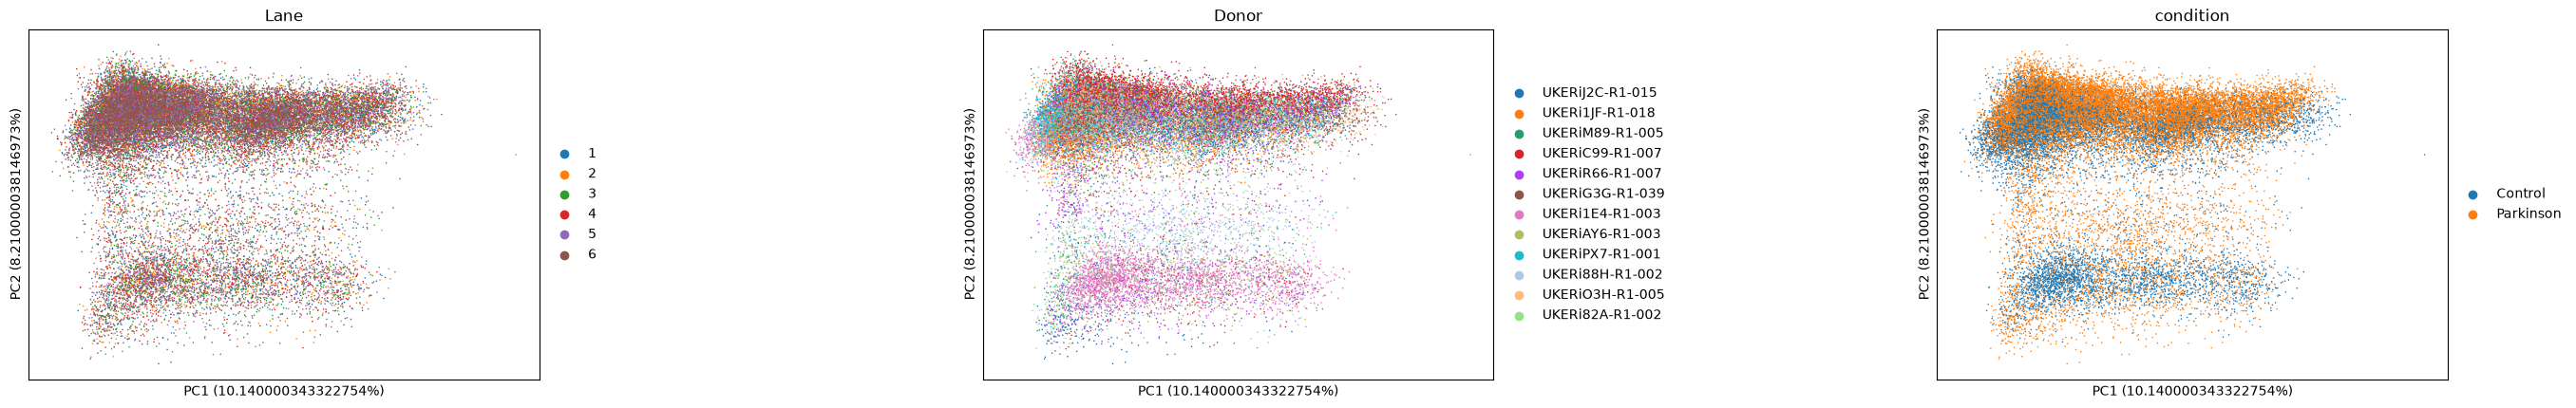

In [14]:
figures_dir = project_root / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig_pca_metadata = sc.pl.pca(
    hvg_input,
    color=["Lane", "Donor", "condition"],
    dimensions=(0, 1),
    ncols=3,
    size=5,
    wspace=0.7,
    annotate_var_explained=True,
    return_fig=True,
    show=False,
)

pca_figures = {
    "pca_explained_variance": fig_pca_variance,
    "pca_by_lane_donor_condition": fig_pca_metadata,
}

for figure_name, figure in pca_figures.items():
    for extension in ["png", "pdf"]:
        figure_path = figures_dir / f"{figure_name}.{extension}"

        figure.savefig(
            figure_path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )

        print("Saved figure:", figure_path.name)

In [15]:
hvg_input.uns["normalization"] = dict(
    normalized_adata.uns["normalization"]
)

hvg_input.uns["feature_selection"] = {
    "min_cells_detected": 3,
    "flavor": "seurat",
    "n_top_genes": n_top_genes,
    "n_selected_genes": n_hvgs,
    "selection_scope": "pooled_lanes",
}

pca_path = (
    project_root / "data" / "interim" / "GSE176160_patients_pca.h5ad"
)
temporary_path = pca_path.with_suffix(".tmp.h5ad")

hvg_input.write_h5ad(temporary_path, compression="gzip")

saved_pca = ad.read_h5ad(temporary_path, backed="r")

try:
    assert saved_pca.shape == hvg_input.shape
    assert saved_pca.obs_names.equals(hvg_input.obs_names)
    assert saved_pca.var_names.equals(hvg_input.var_names)
    assert saved_pca.var["highly_variable"].equals(
        hvg_input.var["highly_variable"]
    )
    assert np.array_equal(saved_pca.obsm["X_pca"], pca_coordinates)
finally:
    saved_pca.file.close()

temporary_path.replace(pca_path)

print("Verified expression shape:", hvg_input.shape)
print("Verified PCA shape:", pca_coordinates.shape)
print("Saved PCA dataset:", pca_path.name)

Verified expression shape: (30589, 32801)
Verified PCA shape: (30589, 50)
Saved PCA dataset: GSE176160_patients_pca.h5ad


## Feature selection and PCA outcome

Of 58,735 genes, 32,801 were detected in at least three cells. The Seurat dispersion method selected 2,000 highly variable genes across the pooled lanes. PCA used these genes to compute 50 components for 30,589 cells. PC1 explained 10.14% of the variance in the selected expression matrix, and the first 10 PCs explained 38.84%.

The six lanes overlapped in the PC1–PC2 projection. After accounting for donor, the largest lane contribution was 2.09% of the remaining variance in PC37. Two control donors contributed approximately 49% of the cells in the lowest PC2 quintile. The marker expression patterns in this region will inform cell-state annotation.

The expression matrix, HVG flags, and PCA coordinates were saved to `data/interim/GSE176160_patients_pca.h5ad`. The initial clustering will use these PCA coordinates and assess lane and donor representation across clusters.